# Parte 3 — Evaluación, métricas y visualización de la CNN

**Proyecto:** clasificación de imágenes de animales (Animals-10).

Este cuaderno continúa las Partes 1 y 2 del repositorio
[wendyalda/Machine-Learning](https://github.com/wendyalda/Machine-Learning).

Genera los entregables solicitados:
- Curvas de exactitud (accuracy) y pérdida (loss) durante el entrenamiento.
- Evaluación de la CNN con el conjunto de **prueba** (`test.csv`, 2618 imágenes).
- Accuracy, precision, recall y F1-score.
- Matriz de confusión y reporte por clase.

**Antes de comenzar:** en tu Google Drive crea (si no existe) la carpeta
`Mi unidad/practica2` y coloca allí estos archivos:

1. `Animals-10.zip` (dataset usado en las Partes 1 y 2).
2. `modelo_cnn_animales.keras` (modelo entrenado por la Parte 2).

Si tu compañero guardó el modelo en `Mi unidad/practica2_mi_unidad`,
este cuaderno también lo busca allí.

> El historial y `test.csv` se leen directamente del repositorio público.
> No es necesario volver a entrenar la CNN. **No mezcles `val.csv` con `test.csv`.**

## 1. Preparar Google Colab y leer el historial de entrenamiento

Ejecuta esta celda. Colab te pedirá autorizar el acceso a tu Google Drive.
Las imágenes resultantes quedarán en `practica2/parte3_resultados/`.

In [1]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from google.colab import drive

drive.mount("/content/drive")

BASE_DIR = Path("/content/drive/MyDrive/practica2")
OUTPUT_DIR = BASE_DIR / "parte3_resultados"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HIST_URL = (
    "https://raw.githubusercontent.com/wendyalda/"
    "Machine-Learning/main/artefactos/historial_entrenamiento.csv"
)
TEST_URL = (
    "https://raw.githubusercontent.com/wendyalda/"
    "Machine-Learning/main/datos/test.csv"
)

# El orden corresponde a sorted(os.listdir(DATA_DIR)) de la Parte 1.
CLASES_ES = [
    "Perro", "Caballo", "Elefante", "Mariposa", "Gallina",
    "Gato", "Vaca", "Oveja", "Araña", "Ardilla"
]
NUM_CLASSES = len(CLASES_ES)
IMG_SIZE = 128
BATCH_SIZE = 32

historial = pd.read_csv(HIST_URL)
columnas_necesarias = {"accuracy", "loss", "val_accuracy", "val_loss"}
assert columnas_necesarias.issubset(historial.columns), (
    f"Columnas inesperadas en el historial: {list(historial.columns)}"
)

print("Épocas registradas:", len(historial))
print("Mejor época según val_loss:", historial["val_loss"].idxmin() + 1)
display(historial.tail())

Mounted at /content/drive
Épocas registradas: 14
Mejor época según val_loss: 9


,accuracy,loss,val_accuracy,val_loss,learning_rate
9,0.674402,0.969822,0.612681,1.174986,0.0010
10,0.680514,0.950733,0.655462,0.995260,0.0010
11,0.687581,0.926391,0.655462,1.054476,0.0010
12,0.723344,0.828030,0.670741,0.979547,0.0005
13,0.731080,0.796657,0.663484,1.033029,0.0005


## 2. Gráfica de exactitud (Accuracy vs. épocas)

Compara el porcentaje de aciertos en entrenamiento y validación.

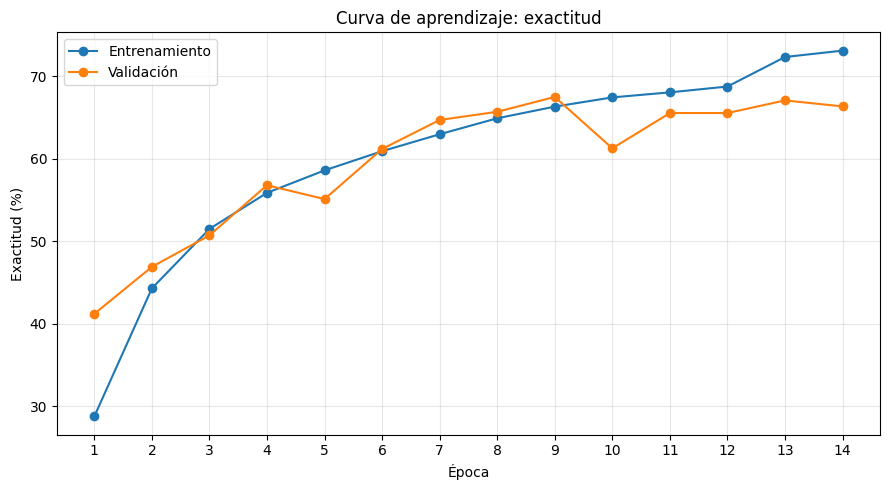

Guardada: /content/drive/MyDrive/practica2/parte3_resultados/curva_accuracy.png


In [2]:
epocas = np.arange(1, len(historial) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epocas, historial["accuracy"] * 100, marker="o",
         label="Entrenamiento")
plt.plot(epocas, historial["val_accuracy"] * 100, marker="o",
         label="Validación")
plt.xlabel("Época")
plt.ylabel("Exactitud (%)")
plt.title("Curva de aprendizaje: exactitud")
plt.xticks(epocas)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "curva_accuracy.png", dpi=180)
plt.show()
print("Guardada:", OUTPUT_DIR / "curva_accuracy.png")

## 3. Gráfica de pérdida (Loss vs. épocas)

Permite detectar si el error de validación deja de disminuir mientras
el error de entrenamiento continúa bajando.

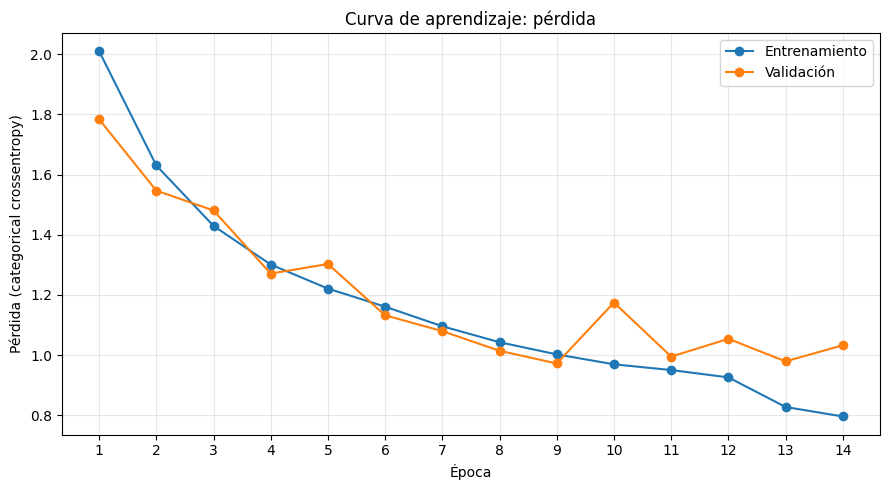

Guardada: /content/drive/MyDrive/practica2/parte3_resultados/curva_loss.png


In [4]:
plt.figure(figsize=(9, 5))
plt.plot(epocas, historial["loss"], marker="o", label="Entrenamiento")
plt.plot(epocas, historial["val_loss"], marker="o", label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida (categorical crossentropy)")
plt.title("Curva de aprendizaje: pérdida")
plt.xticks(epocas)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "curva_loss.png", dpi=180)
plt.show()
print("Guardada:", OUTPUT_DIR / "curva_loss.png")

## 4. Preparar las imágenes de prueba y localizar el modelo entrenado

Esta etapa **sí necesita** `Animals-10.zip` y `modelo_cnn_animales.keras`.

El archivo `test.csv` tiene rutas que comienzan por
`/content/animals10/raw-img/`, así que el ZIP se extrae exactamente en
`/content/animals10` para conservar la correspondencia con la Parte 1.

In [7]:
ZIP_PATH = BASE_DIR / "Animals-10.zip"
EXTRACT_DIR = Path("/content/animals10")
DATA_DIR = EXTRACT_DIR / "raw-img"

if not DATA_DIR.is_dir():
    if not ZIP_PATH.is_file():
        raise FileNotFoundError(
            f"No encuentro {ZIP_PATH}. Copia Animals-10.zip "
            "a Mi unidad/practica2 en tu Drive y vuelve a ejecutar."
        )
    print("Extrayendo Animals-10.zip (solo se hace una vez por sesión)...")
    with zipfile.ZipFile(ZIP_PATH, "r") as archivo_zip:
        archivo_zip.extractall(EXTRACT_DIR)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"No existe {DATA_DIR} después de descomprimir. "
        "Revisa la estructura interna de Animals-10.zip."
    )

opciones_modelo = [
    BASE_DIR / "modelo_cnn_animales.keras",
    Path("/content/drive/MyDrive/practica2_mi_unidad/modelo_cnn_animales.keras")
]
MODEL_PATH = next((p for p in opciones_modelo if p.is_file()), None)
if MODEL_PATH is None:
    raise FileNotFoundError(
        "No encuentro modelo_cnn_animales.keras. Pide el archivo entrenado "
        "de la Parte 2 y guárdalo en Mi unidad/practica2."
    )

test_df = pd.read_csv(TEST_URL)
assert {"ruta", "etiqueta"}.issubset(test_df.columns)
assert test_df["etiqueta"].between(0, NUM_CLASSES - 1).all()

rutas_faltantes = [r for r in test_df["ruta"] if not Path(r).is_file()]
if rutas_faltantes:
    raise FileNotFoundError(
        f"Faltan {len(rutas_faltantes)} imágenes. Primera ruta: "
        f"{rutas_faltantes[0]}. Comprueba el ZIP y su extracción."
    )

print("Modelo encontrado:", MODEL_PATH)
print("Imágenes de prueba:", len(test_df))
print("Clases:", dict(enumerate(CLASES_ES)))

Extrayendo Animals-10.zip (solo se hace una vez por sesión)...
Modelo encontrado: /content/drive/MyDrive/practica2/modelo_cnn_animales.keras
Imágenes de prueba: 2618
Clases: {0: 'Perro', 1: 'Caballo', 2: 'Elefante', 3: 'Mariposa', 4: 'Gallina', 5: 'Gato', 6: 'Vaca', 7: 'Oveja', 8: 'Araña', 9: 'Ardilla'}


## 5. Crear el conjunto de prueba sin mezclar ni aumentar imágenes

Se utiliza exactamente el mismo redimensionamiento y normalización
que en el entrenamiento: **128 × 128** y píxeles en **[0, 1]**.

**Importante:** no hacer `shuffle` ni aplicar `Data Augmentation` a prueba,
para que cada predicción corresponda a la etiqueta correcta.

In [8]:
def cargar_imagen(ruta, etiqueta):
    imagen = tf.io.read_file(ruta)
    imagen = tf.image.decode_image(
        imagen, channels=3, expand_animations=False
    )
    imagen = tf.image.resize(imagen, (IMG_SIZE, IMG_SIZE))
    imagen = imagen / 255.0
    return imagen, tf.one_hot(etiqueta, NUM_CLASSES)

test_ds = tf.data.Dataset.from_tensor_slices((
    test_df["ruta"].astype(str).values,
    test_df["etiqueta"].astype("int32").values
))
test_ds = test_ds.map(cargar_imagen, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

y_real = test_df["etiqueta"].to_numpy(dtype=int)
print("Conjunto de prueba preparado:", len(y_real), "imágenes")

Conjunto de prueba preparado: 2618 imágenes


## 6. Evaluación del modelo CNN en las imágenes de prueba

La función `evaluate` devuelve la pérdida y la exactitud de prueba.
No confundas estos resultados con los valores de validación del historial.

In [9]:
modelo_cnn = tf.keras.models.load_model(str(MODEL_PATH))
assert modelo_cnn.input_shape[-3:] == (128, 128, 3), modelo_cnn.input_shape
assert modelo_cnn.output_shape[-1] == NUM_CLASSES, modelo_cnn.output_shape

resultados_eval = modelo_cnn.evaluate(
    test_ds, verbose=1, return_dict=True
)
perdida_test = float(resultados_eval["loss"])
accuracy_test = float(resultados_eval["accuracy"])

print(f"Pérdida en prueba: {perdida_test:.4f}")
print(f"Accuracy en prueba: {accuracy_test:.4f} "
      f"({accuracy_test * 100:.2f} %)")

probabilidades = modelo_cnn.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilidades, axis=1)
assert len(y_pred) == len(y_real), "No coinciden predicciones y etiquetas"

82/82 ━━━━━━━━━━━━━━━━━━━━ 41s 420ms/step - accuracy: 0.6490 - loss: 1.0216
Pérdida en prueba: 1.0216
Accuracy en prueba: 0.6490 (64.90 %)
82/82 ━━━━━━━━━━━━━━━━━━━━ 34s 391ms/step


## 7. Calcular Accuracy, Precision, Recall y F1-score

Para las 10 clases usamos el promedio **macro** (cada clase tiene el
mismo peso). También se guarda el detalle de cada animal.

In [10]:
metricas = {
    "Accuracy": accuracy_score(y_real, y_pred),
    "Precision_macro": precision_score(
        y_real, y_pred, average="macro", zero_division=0
    ),
    "Recall_macro": recall_score(
        y_real, y_pred, average="macro", zero_division=0
    ),
    "F1_macro": f1_score(
        y_real, y_pred, average="macro", zero_division=0
    ),
    "Loss": perdida_test
}

for nombre, valor in metricas.items():
    print(f"{nombre}: {valor:.4f}"
          + (f" ({valor*100:.2f} %)" if nombre != "Loss" else ""))

pd.DataFrame([metricas]).to_csv(
    OUTPUT_DIR / "metricas_generales.csv", index=False
)

reporte_por_clase = classification_report(
    y_real, y_pred, labels=list(range(NUM_CLASSES)),
    target_names=CLASES_ES, output_dict=True, zero_division=0
)
pd.DataFrame(reporte_por_clase).transpose().to_csv(
    OUTPUT_DIR / "reporte_por_clase.csv", index=True
)
print("\nReporte por categoría:")
print(classification_report(
    y_real, y_pred, labels=list(range(NUM_CLASSES)),
    target_names=CLASES_ES, zero_division=0
))

Accuracy: 0.6490 (64.90 %)
Precision_macro: 0.6244 (62.44 %)
Recall_macro: 0.6344 (63.44 %)
F1_macro: 0.6209 (62.09 %)
Loss: 1.0216

Reporte por categoría:
              precision    recall  f1-score   support

       Perro       0.75      0.57      0.65       487
     Caballo       0.63      0.60      0.62       262
    Elefante       0.59      0.63      0.61       145
    Mariposa       0.59      0.90      0.71       211
     Gallina       0.90      0.69      0.78       310
        Gato       0.59      0.45      0.51       167
        Vaca       0.50      0.53      0.51       186
       Oveja       0.47      0.62      0.53       182
       Araña       0.79      0.78      0.78       482
     Ardilla       0.45      0.58      0.50       186

    accuracy                           0.65      2618
   macro avg       0.62      0.63      0.62      2618
weighted avg       0.67      0.65      0.65      2618



## 8. Matriz de confusión

- **Filas:** animal real.
- **Columnas:** animal predicho por la CNN.
- **Diagonal:** predicciones correctas.
- **Fuera de la diagonal:** errores de clasificación.

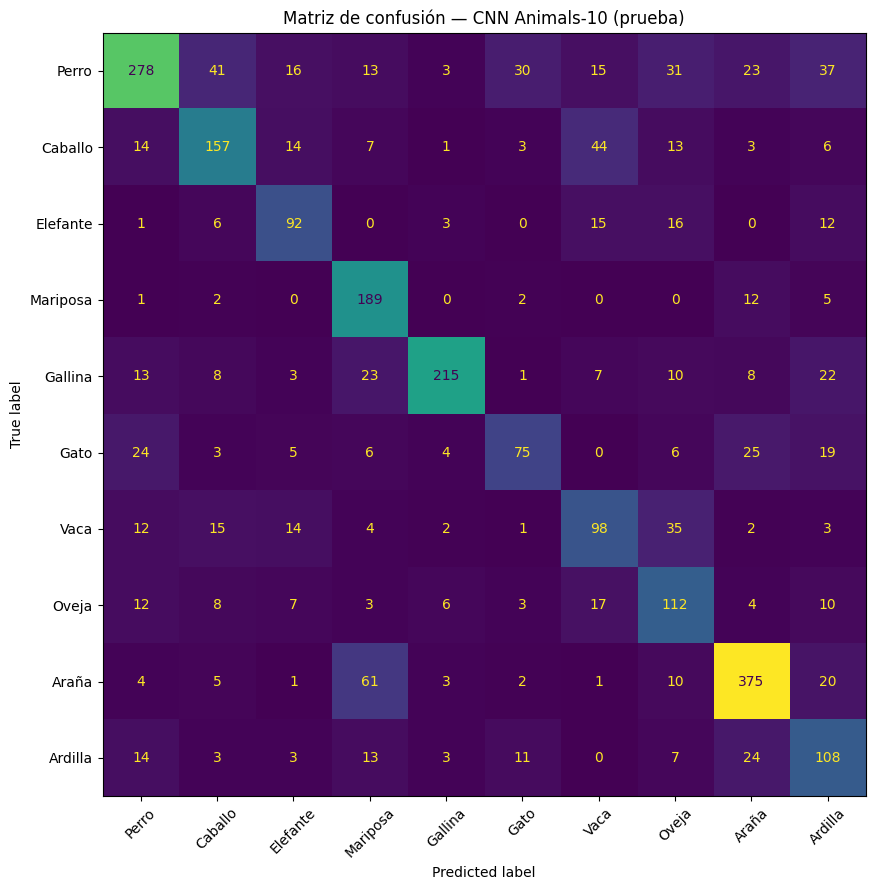

Matriz guardada: /content/drive/MyDrive/practica2/parte3_resultados/matriz_confusion.png


In [11]:
matriz = confusion_matrix(
    y_real, y_pred, labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(11, 9))
visualizador = ConfusionMatrixDisplay(
    confusion_matrix=matriz, display_labels=CLASES_ES
)
visualizador.plot(
    ax=ax, values_format="d", xticks_rotation=45, colorbar=False
)
ax.set_title("Matriz de confusión — CNN Animals-10 (prueba)")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "matriz_confusion.png", dpi=180)
plt.show()

pd.DataFrame(
    matriz, index=CLASES_ES, columns=CLASES_ES
).to_csv(OUTPUT_DIR / "matriz_confusion.csv")
print("Matriz guardada:", OUTPUT_DIR / "matriz_confusion.png")

## 9. Resumen para presentar al profesor

Ejecuta esta celda después de las anteriores. Los resultados aparecen
con los **valores reales** que produjo tu modelo, sin inventar métricas.

In [12]:
mejor_epoca = historial["val_loss"].idxmin() + 1

print("RESUMEN — PARTE 3")
print("=" * 60)
print(f"Se evaluó la CNN de Animals-10 con {len(test_df)} "
      "imágenes del conjunto de prueba.")
print(f"Exactitud en prueba: {metricas['Accuracy']*100:.2f} %")
print(f"Precisión macro: {metricas['Precision_macro']*100:.2f} %")
print(f"Sensibilidad macro: {metricas['Recall_macro']*100:.2f} %")
print(f"F1-score macro: {metricas['F1_macro']*100:.2f} %")
print(f"Pérdida en prueba: {metricas['Loss']:.4f}")
print(f"Mejor época de validación según pérdida: {mejor_epoca}")
print("Se generaron las curvas de aprendizaje y la matriz de confusión.")
print(f"Resultados guardados en: {OUTPUT_DIR}")

RESUMEN — PARTE 3
Se evaluó la CNN de Animals-10 con 2618 imágenes del conjunto de prueba.
Exactitud en prueba: 64.90 %
Precisión macro: 62.44 %
Sensibilidad macro: 63.44 %
F1-score macro: 62.09 %
Pérdida en prueba: 1.0216
Mejor época de validación según pérdida: 9
Se generaron las curvas de aprendizaje y la matriz de confusión.
Resultados guardados en: /content/drive/MyDrive/practica2/parte3_resultados


## Archivos de salida

Se guardan automáticamente en `Mi unidad/practica2/parte3_resultados/`:

- `curva_accuracy.png`
- `curva_loss.png`
- `metricas_generales.csv`
- `reporte_por_clase.csv`
- `matriz_confusion.png`
- `matriz_confusion.csv`

Para integrarlos en el repositorio del grupo, se recomienda guardar este
cuaderno como `codigo/Parte3_evaluacion_cnn_animales.ipynb` y subir únicamente
los gráficos/CSV de resultados. No es necesario subir las imágenes originales
ni el modelo grande a GitHub.